## Trying segmentation

In [ ]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt

# project folder = parent of notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_2D = ROOT / "data" / "test_images" / "2d"
sys.path.append(str(ROOT))

from src.background_removal import load_rgb, remove_background
from src.segmentation import segment, colorize

def show(images, titles=None, size=5):
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    for ax, img, t in zip(axes, images, titles or [""] * len(images)):
        ax.imshow(img, cmap="gray" if img.ndim == 2 else None)
        ax.set_title(t)
        ax.axis("off")
    plt.show()

16 pieces


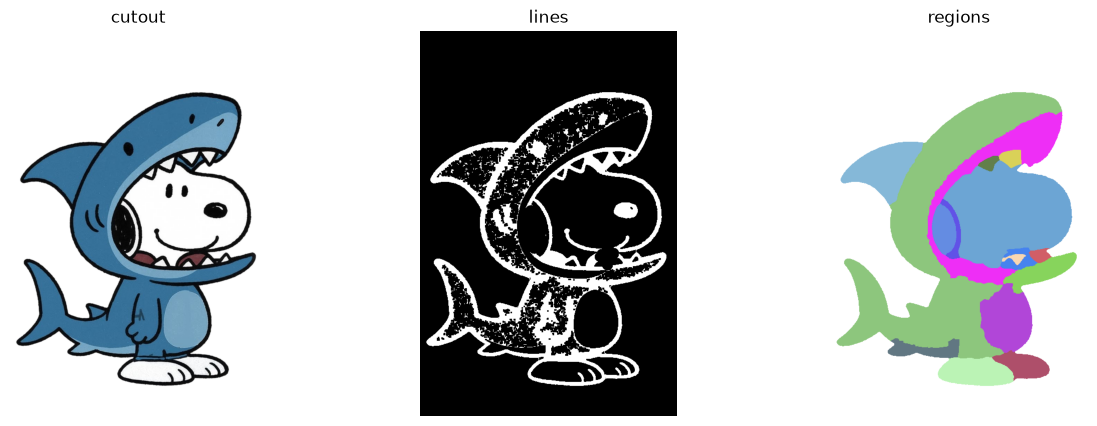

In [8]:
rgba, _ = remove_background(load_rgb(DATA_2D / "hard" / "4h.jpg", 768))
regions, lines = segment(rgba)
print(regions.max(), "pieces")
show([rgba, lines, colorize(regions)], ["cutout", "lines", "regions"])